# Data Exploration (about 25% of the notebook)
- Basic stats (size, missing values, target distribution if applicable)
- Text length distribution, sample examples

Data is found here: https://www.kaggle.com/datasets/gpreda/reddit-wallstreetsbets-posts?utm_source=chatgpt.com

In [3]:
from pathlib import Path
import pandas as pd

# Load the original dataset without changing it
data_path = Path("../data/raw/reddit_wsb.csv")
df_raw = pd.read_csv(data_path)

print(f"Posts: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")

df_raw.head()

Posts: 53,187
Columns: 8


,title,score,id,url,comms_num,created,body,timestamp
0,"It's not about the money, it's about sending a...",55,l6ulcx,https://v.redd.it/6j75regs72e61,6,1.611863e+09,NaN,2021-01-28 21:37:41
1,Math Professor Scott Steiner says the numbers ...,110,l6uibd,https://v.redd.it/ah50lyny62e61,23,1.611862e+09,NaN,2021-01-28 21:32:10
2,Exit the system,0,l6uhhn,https://www.reddit.com/r/wallstreetbets/commen...,47,1.611862e+09,The CEO of NASDAQ pushed to halt trading “to g...,2021-01-28 21:30:35
3,NEW SEC FILING FOR GME! CAN SOMEONE LESS RETAR...,29,l6ugk6,https://sec.report/Document/0001193125-21-019848/,74,1.611862e+09,NaN,2021-01-28 21:28:57
4,"Not to distract from GME, just thought our AMC...",71,l6ufgy,https://i.redd.it/4h2sukb662e61.jpg,156,1.611862e+09,NaN,2021-01-28 21:26:56


In [4]:
# Column types and missing values
data_summary = pd.DataFrame({
    "data_type": df_raw.dtypes,
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2)
})

display(data_summary)

print(f"Duplicate rows: {df_raw.duplicated().sum():,}")
print(f"Duplicate post IDs: {df_raw['id'].duplicated().sum():,}")

,data_type,missing_count,missing_pct
title,object,0,0.00
score,int64,0,0.00
id,object,0,0.00
url,object,0,0.00
comms_num,int64,0,0.00
created,float64,0,0.00
body,object,28449,53.49
timestamp,object,0,0.00


Duplicate rows: 0
Duplicate post IDs: 0


## Date Coverage

We examine posting dates and daily post counts to identify gaps and
uneven coverage before selecting an analysis period. Dates without
records cannot automatically be treated as days with no Reddit activity.

In [5]:
# Create a working copy and convert Unix timestamps to UTC
df = df_raw.copy()

df["created_utc"] = pd.to_datetime(
    df["created"], unit="s", utc=True, errors="coerce"
)

print("Earliest post:", df["created_utc"].min())
print("Latest post:", df["created_utc"].max())
print("Invalid timestamps:", df["created_utc"].isna().sum())

# Count posts on each observed UTC date
daily_counts = (
    df.groupby(df["created_utc"].dt.floor("D"))
    .size()
    .rename("post_count")
    .sort_index()
)

print("Dates with posts:", len(daily_counts))
display(daily_counts.head(10))

Earliest post: 2020-09-29 00:46:56+00:00
Latest post: 2021-08-16 06:26:20+00:00
Invalid timestamps: 0
Dates with posts: 176


created_utc
2020-09-29 00:00:00+00:00       1
2021-01-28 00:00:00+00:00    8447
2021-01-29 00:00:00+00:00    8938
2021-01-30 00:00:00+00:00    1044
2021-01-31 00:00:00+00:00     895
2021-02-01 00:00:00+00:00    1154
2021-02-02 00:00:00+00:00    1963
2021-02-03 00:00:00+00:00    2098
2021-02-04 00:00:00+00:00    1578
2021-02-05 00:00:00+00:00    2856
Name: post_count, dtype: int64

Dates without records: 26
['2021-05-02', '2021-05-03', '2021-05-04', '2021-06-02', '2021-06-03', '2021-06-04', '2021-06-05', '2021-06-06', '2021-06-07', '2021-06-08', '2021-06-09', '2021-06-13', '2021-06-14', '2021-06-27', '2021-07-21', '2021-07-22', '2021-07-23', '2021-07-24', '2021-07-25', '2021-07-26', '2021-07-27', '2021-07-28', '2021-07-29', '2021-07-30', '2021-07-31', '2021-08-01']


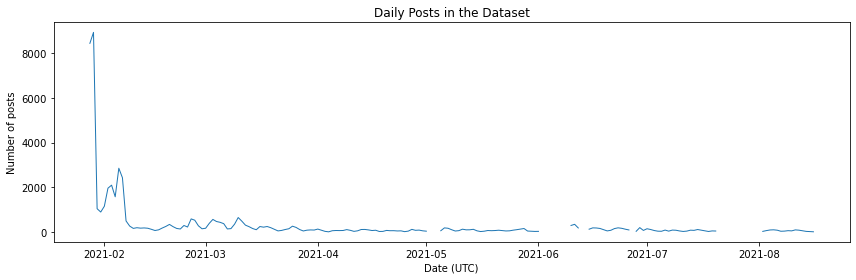

In [6]:
import matplotlib.pyplot as plt

# Inspect the main period without removing rows from df
main_counts = daily_counts.loc["2021-01-01":]

calendar_dates = pd.date_range(
    main_counts.index.min(),
    main_counts.index.max(),
    freq="D"
)

# Leave dates without records as missing
coverage = main_counts.reindex(calendar_dates)
missing_dates = coverage.index[coverage.isna()]

print(f"Dates without records: {len(missing_dates)}")
print(missing_dates.strftime("%Y-%m-%d").tolist())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(coverage.index, coverage, linewidth=1)
ax.set(
    title="Daily Posts in the Dataset",
    xlabel="Date (UTC)",
    ylabel="Number of posts"
)
plt.tight_layout()
plt.show()

### Date Coverage Findings

Recorded post counts vary substantially across the dataset, with the
highest counts in late January and early February 2021. There are
26 dates without records between January 28 and August 16. These gaps
are treated as missing coverage rather than confirmed zero activity.

Changes in recorded counts may reflect both Reddit activity and the
collection process. January 29–April 30 is a candidate analysis window
because every UTC calendar date has records, although this does not
guarantee complete collection. The final window will be selected after
examining ticker coverage.

In [7]:
# Combine title and body while keeping capitalization and punctuation
df["post_text"] = (
    df["title"].fillna("") + "\n" + df["body"].fillna("")
).str.strip()

df["word_count"] = df["post_text"].str.split().str.len()
df["character_count"] = df["post_text"].str.len()

display(
    df[["word_count", "character_count"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
    .round(1)
)

print("Empty combined texts:", df["post_text"].eq("").sum())

,word_count,character_count
count,53187.0,53187.0
mean,111.4,696.2
std,289.3,1861.8
min,1.0,1.0
25%,8.0,45.0
50%,18.0,101.0
75%,82.0,495.0
95%,524.7,3244.4
99%,1381.1,8817.1
max,6461.0,39749.0


Empty combined texts: 0


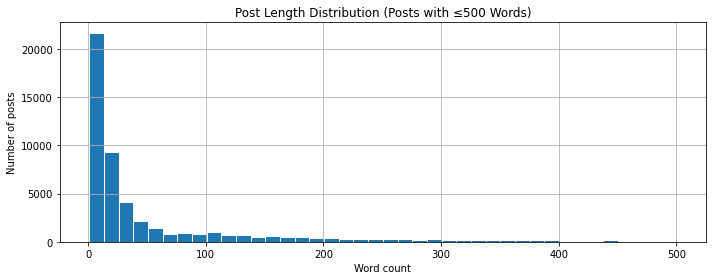

Posts above the displayed range: 2,815


In [8]:
# Limit the displayed range so long posts do not compress the chart
display_limit = 500

fig, ax = plt.subplots(figsize=(10, 4))

df.loc[df["word_count"] <= display_limit, "word_count"].hist(
    bins=40, ax=ax, edgecolor="white"
)

ax.set(
    title="Post Length Distribution (Posts with ≤500 Words)",
    xlabel="Word count",
    ylabel="Number of posts"
)

plt.tight_layout()
plt.show()

print(
    "Posts above the displayed range:",
    f'{(df["word_count"] > display_limit).sum():,}'
)

### Text Length Findings

Post lengths are strongly right-skewed. The median is 18 words,
compared with a mean of 111.4 words, indicating that relatively long
posts pull the average upward. The histogram displays posts containing
500 words or fewer for readability; 2,815 longer posts remain in the
dataset.

This variation supports scoring individual posts before aggregating
sentiment to ticker-day features, so longer posts do not automatically
receive more weight simply because they contain more words.

In [9]:
# Show reproducible examples with shortened previews
sample_posts = df[
    ["created_utc", "title", "post_text", "word_count"]
].sample(5, random_state=42).copy()

sample_posts["text_preview"] = sample_posts["post_text"].str.slice(0, 400)

display(
    sample_posts[
        ["created_utc", "title", "word_count", "text_preview"]
    ]
)

,created_utc,title,word_count,text_preview
42975,2021-03-23 21:15:11+00:00,WSB Rules - Please Read Before Posting,449,WSB Rules - Please Read Before Posting\n# Welc...
4305,2021-01-28 23:20:21+00:00,Trading 212 wont give this retard an account :(,27,Trading 212 wont give this retard an account :...
4813,2021-01-28 23:22:26+00:00,They're saying we throttled but we're higher a...,15,They're saying we throttled but we're higher a...
9281,2021-01-29 00:07:34+00:00,Vy Global Growth (VYGG): Low-risk investment i...,670,Vy Global Growth (VYGG): Low-risk investment i...
23686,2021-02-03 08:36:12+00:00,Weed bet I'm holding for the next few months. ...,26,Weed bet I'm holding for the next few months. ...


## Ticker Coverage

We identify uppercase ticker symbols, with or without a dollar sign.
Each ticker is counted once per post, even if repeated. Posts mentioning
multiple tickers contribute to each ticker's count. These initial matches
will require manual checking for ambiguous symbols.

In [10]:
import re

TICKERS = [
    "AAPL", "MSFT", "NVDA", "TSLA", "GME",
    "PLTR", "AMD", "COIN", "HOOD", "SOFI"
]

ticker_pattern = re.compile(
    r"(?<!\w)\$?(" + "|".join(TICKERS) + r")(?!\w)"
)

def extract_tickers(text):
    """Return unique tracked uppercase tickers in a post."""
    return sorted(set(ticker_pattern.findall(text)))

df["tickers"] = df["post_text"].apply(extract_tickers)

ticker_counts = (
    df["tickers"]
    .explode()
    .value_counts()
    .reindex(TICKERS, fill_value=0)
    .sort_values(ascending=False)
    .rename_axis("ticker")
    .reset_index(name="post_count")
)

display(ticker_counts)

print("Posts with a tracked ticker:", df["tickers"].str.len().gt(0).sum())
print("Posts with multiple tracked tickers:", df["tickers"].str.len().gt(1).sum())

,ticker,post_count
0,GME,12970
1,PLTR,797
2,TSLA,575
3,AMD,367
4,AAPL,228
5,NVDA,105
6,MSFT,99
7,SOFI,94
8,HOOD,63
9,COIN,52


Posts with a tracked ticker: 14535
Posts with multiple tracked tickers: 600


In [11]:
# One row per post–ticker pair
post_tickers = (
    df[["id", "created_utc", "tickers"]]
    .explode("tickers")
    .dropna(subset=["tickers"])
    .rename(columns={"tickers": "ticker"})
)

post_tickers["date_utc"] = post_tickers["created_utc"].dt.floor("D")

ticker_coverage = (
    post_tickers.groupby("ticker")
    .agg(
        post_count=("id", "nunique"),
        dates_with_mentions=("date_utc", "nunique"),
        first_mention=("created_utc", "min"),
        last_mention=("created_utc", "max")
    )
    .sort_values("post_count", ascending=False)
)

display(ticker_coverage)

,post_count,dates_with_mentions,first_mention,last_mention
ticker,,,,
GME,12970,170,2021-01-28 07:08:18+00:00,2021-08-14 17:34:20+00:00
PLTR,797,138,2021-01-28 10:52:24+00:00,2021-08-14 06:22:46+00:00
TSLA,575,140,2021-01-28 11:26:17+00:00,2021-08-11 19:21:14+00:00
AMD,367,129,2021-01-28 11:26:17+00:00,2021-08-12 01:07:52+00:00
AAPL,228,110,2021-01-28 23:03:58+00:00,2021-08-11 13:36:52+00:00
NVDA,105,61,2021-01-28 23:03:34+00:00,2021-08-16 02:00:59+00:00
MSFT,99,66,2021-01-28 23:03:58+00:00,2021-08-13 14:59:58+00:00
SOFI,94,32,2021-01-28 23:16:45+00:00,2021-08-13 12:01:05+00:00
HOOD,63,19,2021-01-28 21:40:31+00:00,2021-08-13 16:20:14+00:00


In [12]:
# Inspect ticker coverage within the candidate window
window_posts = post_tickers.loc[
    (post_tickers["created_utc"] >= "2021-01-29") &
    (post_tickers["created_utc"] < "2021-05-01")
]

window_coverage = (
    window_posts.groupby("ticker")
    .agg(
        post_count=("id", "nunique"),
        dates_with_mentions=("date_utc", "nunique")
    )
    .reindex(TICKERS, fill_value=0)
    .sort_values("post_count", ascending=False)
)

display(window_coverage)

,post_count,dates_with_mentions
ticker,,
GME,10386,92
PLTR,595,83
TSLA,422,85
AMD,201,74
AAPL,149,65
MSFT,70,41
NVDA,48,28
HOOD,18,6
SOFI,18,6


### Preliminary Ticker Selection

GME, PLTR, TSLA, AMD, and AAPL have the broadest discussion coverage
during January 29–April 30, 2021, appearing on 65–92 calendar dates.
These five are provisional candidates for the next stage.

GME dominates the sample, so results may be disproportionately influenced
by this stock. MSFT and NVDA have sparser coverage, while HOOD, SOFI,
and COIN have too few observed mentions in this window to support
reliable daily sentiment summaries.

Final inclusion will also depend on manual validation of ticker matches
and sufficient historical trading-volume data. Calendar dates with
mentions are not equivalent to trading-day observations.

In [13]:
candidate_tickers = ["GME", "PLTR", "TSLA", "AMD", "AAPL"]

for ticker in candidate_tickers:
    matches = df.loc[
        (df["created_utc"] >= "2021-01-29") &
        (df["created_utc"] < "2021-05-01") &
        df["tickers"].apply(lambda tickers: ticker in tickers)
    ]

    print(f"\n--- {ticker}: sample matches ---")

    for text in matches["post_text"].sample(
        min(3, len(matches)), random_state=42
    ):
        match = re.search(rf"(?<!\w)\$?{ticker}(?!\w)", text)
        start = max(0, match.start() - 100)
        end = min(len(text), match.end() + 200)
        print(text[start:end].replace("\n", " "))
        print()


--- GME: sample matches ---
of Ryan Cohen’s tweet earlier today.   Here’s a take:  RC Ventures currently holds a 12.9% stake in GME with clearance to purchase up to a 19.9% stake (see form 8-K for standstill provision timelines). He tweeted a still from Pets.com at 2:19pm EST, shortly after the tweet GME went fucking vertical. Ri

Serious GME question So, I have almost zero experience in buying/trading stocks and I don't even really have a good grasp on margins and options but here is my question regarding GME and it's current state;  Wou

My YOLO account. Buying $GME on the dips 10 shares at a time, only wish I had gotten in sooner! HOLD! 🤚💎✋🚀🚀🚀🚀


--- PLTR: sample matches ---
33k YOLO on PLTR b/c only 🚀🚀 from here on right...??

PLTR 💎🙌

d comparable is Palantir at \~44x. Bulls (aka Wall Street’s sycophantic sell side analysts) may use PLTR as a lame justification for C3’s current valuations, but unlike C3 Palantir is actually looking at real 45% QoQ revenue growth—more than DOUBLE 

### Initial Manual Check of Ticker Matches

We inspected three sampled posts for each of five candidate tickers
(15 post–ticker examples). All displayed matches appeared to refer to
the intended companies. This small check does not establish accuracy
across the full dataset or measure missed mentions.

Some companies were mentioned only as comparisons or background
information. We count these as mentions, but they do not necessarily
indicate sentiment toward that company. In Phase III, Claude will be
prompted to assess sentiment toward each specified ticker and allow
neutral or unclear labels when no directional opinion is expressed.

## Provisional Analysis Subset

In [14]:
SELECTED_TICKERS = ["GME", "PLTR", "TSLA", "AMD", "AAPL"]

df_analysis = df.loc[
    (df["created_utc"] >= "2021-01-29") &
    (df["created_utc"] < "2021-05-01")
].copy()

df_analysis["selected_tickers"] = df_analysis["tickers"].apply(
    lambda tickers: [t for t in tickers if t in SELECTED_TICKERS]
)

print(f"All posts in candidate window: {len(df_analysis):,}")
print(
    "Posts mentioning selected tickers:",
    f'{df_analysis["selected_tickers"].str.len().gt(0).sum():,}'
)

All posts in candidate window: 37,534
Posts mentioning selected tickers: 11,265


In [15]:
expected_dates = pd.date_range(
    "2021-01-29", "2021-04-30", freq="D", tz="UTC"
)

observed_dates = pd.DatetimeIndex(
    df_analysis["created_utc"].dt.floor("D").unique()
)

missing_dates_subset = expected_dates.difference(observed_dates)

print("Expected calendar dates:", len(expected_dates))
print("Dates with posts:", len(observed_dates))
print("Dates without records:", len(missing_dates_subset))

Expected calendar dates: 92
Dates with posts: 92
Dates without records: 0


### Provisional Analysis Subset

The provisional subset covers January 29–April 30, 2021, with posts
recorded on all 92 UTC calendar dates. This confirms that no entire
dates are absent, but does not establish complete collection within
each day.

We provisionally focus on GME, PLTR, TSLA, AMD, and AAPL. All posts
within the window are retained so total recorded activity can be used
to calculate each ticker's share of posts. A date without a detected
ticker mention means zero observed mentions in this dataset, not
necessarily zero discussion across Reddit.

In [16]:
# Total recorded posts per date
daily_totals = (
    df_analysis.groupby(df_analysis["created_utc"].dt.floor("D"))
    .size()
    .rename("total_posts")
)
daily_totals.index.name = "date_utc"

# One row per post–ticker pair
mentions = (
    df_analysis[["id", "created_utc", "selected_tickers"]]
    .explode("selected_tickers")
    .dropna(subset=["selected_tickers"])
    .rename(columns={"selected_tickers": "ticker"})
)

mentions["date_utc"] = mentions["created_utc"].dt.floor("D")

# Include every selected ticker on all 92 dates
full_index = pd.MultiIndex.from_product(
    [expected_dates, SELECTED_TICKERS],
    names=["date_utc", "ticker"]
)

daily_mentions = (
    mentions.groupby(["date_utc", "ticker"])["id"]
    .nunique()
    .reindex(full_index, fill_value=0)
    .rename("mention_count")
    .reset_index()
    .merge(daily_totals.reset_index(), on="date_utc", how="left")
)

daily_mentions["mention_share"] = (
    daily_mentions["mention_count"] / daily_mentions["total_posts"]
)

print("Ticker-date rows:", len(daily_mentions))
display(daily_mentions.head(10))

Ticker-date rows: 460


,date_utc,ticker,mention_count,total_posts,mention_share
0,2021-01-29 00:00:00+00:00,GME,2797,8938,0.312934
1,2021-01-29 00:00:00+00:00,PLTR,26,8938,0.002909
2,2021-01-29 00:00:00+00:00,TSLA,20,8938,0.002238
3,2021-01-29 00:00:00+00:00,AMD,8,8938,0.000895
4,2021-01-29 00:00:00+00:00,AAPL,6,8938,0.000671
5,2021-01-30 00:00:00+00:00,GME,403,1044,0.386015
6,2021-01-30 00:00:00+00:00,PLTR,8,1044,0.007663
7,2021-01-30 00:00:00+00:00,TSLA,14,1044,0.013410
8,2021-01-30 00:00:00+00:00,AMD,8,1044,0.007663
9,2021-01-30 00:00:00+00:00,AAPL,7,1044,0.006705


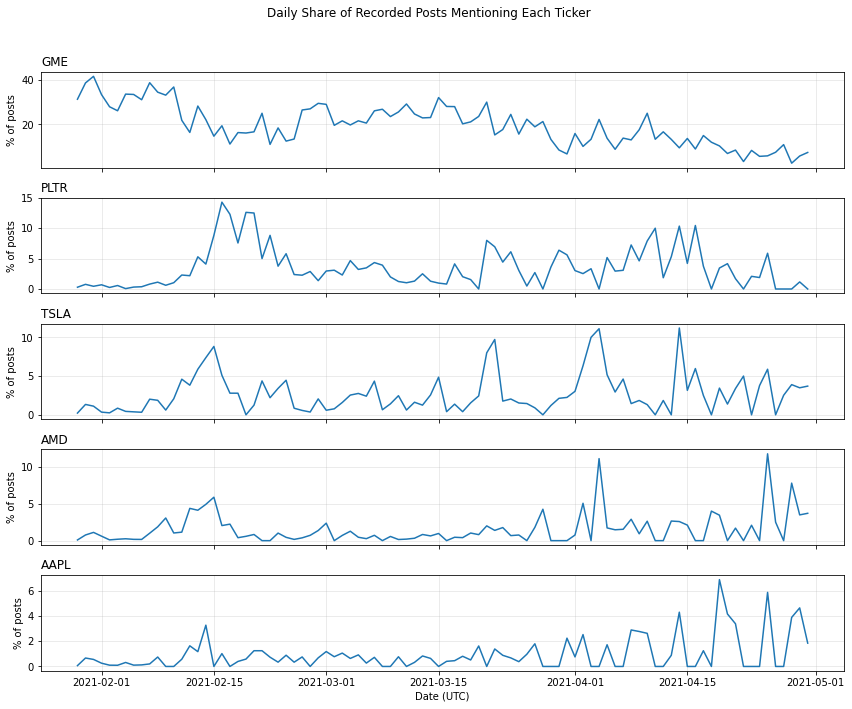

In [17]:
fig, axes = plt.subplots(
    len(SELECTED_TICKERS), 1,
    figsize=(12, 10), sharex=True
)

for ax, ticker in zip(axes, SELECTED_TICKERS):
    ticker_data = daily_mentions.loc[
        daily_mentions["ticker"] == ticker
    ]

    ax.plot(
        ticker_data["date_utc"],
        ticker_data["mention_share"] * 100
    )
    ax.set_title(ticker, loc="left")
    ax.set_ylabel("% of posts")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date (UTC)")
fig.suptitle("Daily Share of Recorded Posts Mentioning Each Ticker")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Daily Attention Patterns

GME accounts for the largest share of recorded posts, although its share
generally declines across the selected period. PLTR shows a pronounced
February peak, while TSLA, AMD, and AAPL display intermittent increases.

These patterns motivate testing whether changes in attention help predict
next-day trading-volume spikes. The charts alone do not establish that
relationship. Mention shares can also rise because total recorded posts
decline, so counts and shares should be considered together.

Each panel uses a different vertical scale. These are descriptive UTC
calendar-day summaries; prediction features will require an explicit
cutoff and alignment with trading days.

In [18]:
daily_summary = daily_mentions.groupby("ticker").agg(
    total_mentions=("mention_count", "sum"),
    median_daily_mentions=("mention_count", "median"),
    zero_mention_dates=("mention_count", lambda x: x.eq(0).sum()),
    mean_daily_share=("mention_share", "mean")
)

daily_summary["mean_daily_share_pct"] = (
    daily_summary.pop("mean_daily_share") * 100
)

display(daily_summary.round(2))

,total_mentions,median_daily_mentions,zero_mention_dates,mean_daily_share_pct
ticker,,,,
AAPL,149,1.0,27,0.97
AMD,201,2.0,18,1.54
GME,10386,31.5,0,19.64
PLTR,595,5.0,9,3.50
TSLA,422,3.0,7,2.71


### Daily Mention Coverage

GME has the strongest coverage, with a median of 31.5 mentioning posts
per calendar date and no zero-mention dates. PLTR and TSLA have medians
of five and three posts, respectively. AMD and AAPL have medians of
two and one, with 18 and 27 zero-mention dates.

Daily sentiment estimates based on only one or two posts may be
unstable. We will retain mention counts alongside sentiment features
and distinguish dates with no observed mentions from dates containing
neutral sentiment.

Mean daily mention share gives each calendar date equal weight; it
is not the proportion of all posts across the entire period.